# Machine Learning - Niveau 1

Ce notebook construit pas à pas un premier classificateur à partir des données Bank Marketing.

## 1. Le problème métier

Une banque mène des campagnes de prospection téléphonique. Elle souhaite mieux prioriser les clients susceptibles de souscrire à un dépôt à terme.

La question d'apprentissage est : **à partir des informations disponibles avant le premier appel, peut-on estimer si un client souscrira (`yes`) ou non (`no`) ?**

Il s'agit d'une **classification binaire supervisée** : les exemples historiques contiennent des caractéristiques (`X`) et une réponse connue (`y`). Le notebook suit ce parcours : comprendre les données, définir la cible, séparer les observations, comparer des modèles et évaluer le modèle retenu sur des données jamais utilisées pendant l'apprentissage.

Source du jeu de données : https://archive.ics.uci.edu/dataset/222/bank+marketing

## 2. Préparer l'accès aux données

Le notebook attend le fichier `donnees_drive/TAB/bank-full.feather`. La cellule suivante le télécharge depuis le dossier Drive partagé ; si le fichier est déjà présent, le téléchargement peut être ignoré.

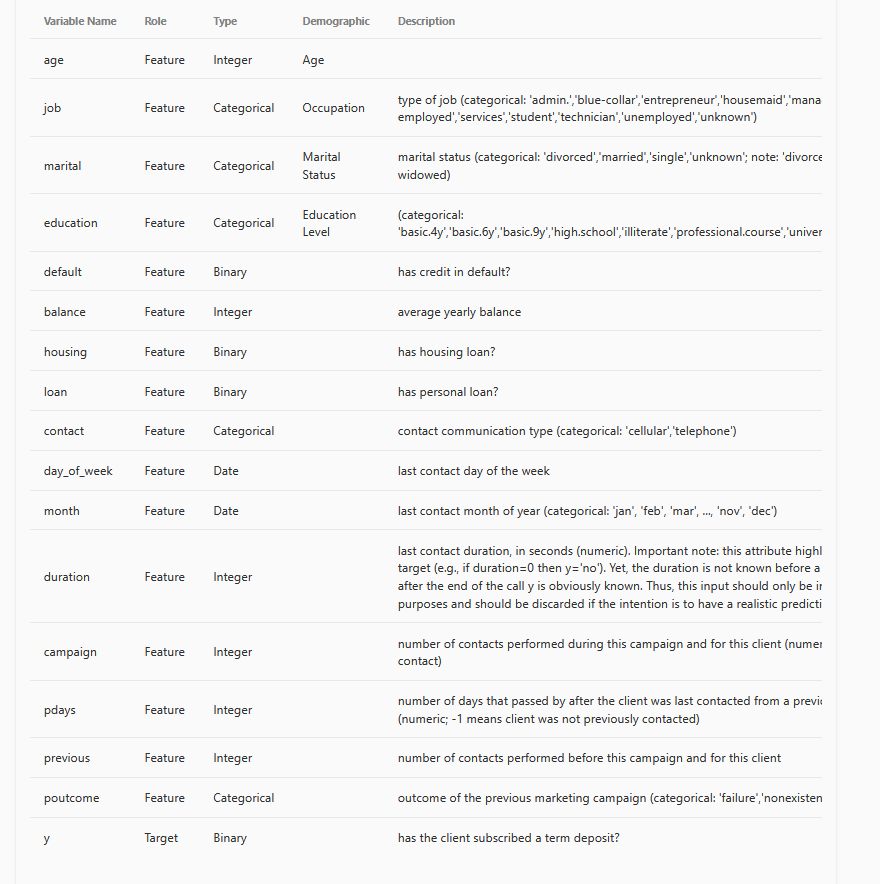

### Installer les dépendances

In [3]:
%pip install gdown pandas pyarrow scikit-learn matplotlib

  Using cached scikit_learn-1.9.1-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (9.3 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached scikit_learn-1.9.1-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (9.2 MB)
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)
Using cached threadpoolctl-3.7.0-py3-none-any.whl (26 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [scikit-learn]0m 3/4 [scikit-learn]

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [4]:
import os

# Lien du dossier Google Drive partagé
folder_url = "https://drive.google.com/drive/folders/1xWsjHmxq0wlsVqF_60ih8_cPAXNY302j?usp=sharing"
output_dir = "donnees_drive"
file_path = os.path.join(output_dir, "TAB", "bank-full.feather")

if os.path.exists(file_path):
    print(f"Fichier déjà présent : {file_path}")
else:
    import gdown

    gdown.download_folder(
        url=folder_url,
        output=output_dir,
        quiet=False,
        use_cookies=False,
    )
    if os.path.exists(file_path):
        print(f"Fichier téléchargé : {file_path}")
    else:
        print(
            "Téléchargement échoué. Vérifie que le dossier Drive est partagé "
            "avec les utilisateurs disposant du lien."
        )

Fichier déjà présent : donnees_drive/TAB/bank-full.feather


## 3. Charger et observer le jeu de données

Le fichier fourni contient les lignes brutes dans une colonne Feather. La cellule suivante reconstruit les colonnes du tableau, convertit les variables numériques et vérifie le nombre de lignes et de colonnes.

In [5]:
import pandas as pd

# Chemin vers le fichier feather téléchargé
file_path = 'donnees_drive/TAB/bank-full.feather'

# Lecture du fichier
temp_df = pd.read_feather(file_path)

# Récupération de la seule colonne contenant les données brutes
raw_col = temp_df.columns[0]

# Recréation d'un DataFrame propre en splittant le texte par le point-virgule
columns = [col.replace('"', '') for col in raw_col.split(';')]
split_data = temp_df[raw_col].apply(lambda x: [val.replace('"', '') if isinstance(val, str) else val for val in str(x).split(';')]).tolist()

# On recrée le DataFrame final
df = pd.DataFrame(split_data, columns=columns)

# Conversion propre des types numériques sans générer de warning de dépréciation
for col in df.columns:
    try:
        df[col] = pd.to_numeric(df[col])
    except (ValueError, TypeError):
        pass

# Affichage des informations réelles du dataset
print(f"Le jeu de données contient désormais {df.shape[0]} lignes et {df.shape[1]} colonnes.")
display(df.head(10))
display(df.tail(10))

Le jeu de données contient désormais 45211 lignes et 17 colonnes.


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no
5,35,management,married,tertiary,no,231,yes,no,unknown,5,may,139,1,-1,0,unknown,no
6,28,management,single,tertiary,no,447,yes,yes,unknown,5,may,217,1,-1,0,unknown,no
7,42,entrepreneur,divorced,tertiary,yes,2,yes,no,unknown,5,may,380,1,-1,0,unknown,no
8,58,retired,married,primary,no,121,yes,no,unknown,5,may,50,1,-1,0,unknown,no
9,43,technician,single,secondary,no,593,yes,no,unknown,5,may,55,1,-1,0,unknown,no


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
45201,53,management,married,tertiary,no,583,no,no,cellular,17,nov,226,1,184,4,success,yes
45202,34,admin.,single,secondary,no,557,no,no,cellular,17,nov,224,1,-1,0,unknown,yes
45203,23,student,single,tertiary,no,113,no,no,cellular,17,nov,266,1,-1,0,unknown,yes
45204,73,retired,married,secondary,no,2850,no,no,cellular,17,nov,300,1,40,8,failure,yes
45205,25,technician,single,secondary,no,505,no,yes,cellular,17,nov,386,2,-1,0,unknown,yes
45206,51,technician,married,tertiary,no,825,no,no,cellular,17,nov,977,3,-1,0,unknown,yes
45207,71,retired,divorced,primary,no,1729,no,no,cellular,17,nov,456,2,-1,0,unknown,yes
45208,72,retired,married,secondary,no,5715,no,no,cellular,17,nov,1127,5,184,3,success,yes
45209,57,blue-collar,married,secondary,no,668,no,no,telephone,17,nov,508,4,-1,0,unknown,no
45210,37,entrepreneur,married,secondary,no,2971,no,no,cellular,17,nov,361,2,188,11,other,no


## 4. Explorer la qualité et la cible

Avant d'entraîner un modèle, on vérifie la structure, les valeurs inconnues et la répartition des réponses. Le mot `unknown` est une catégorie explicite du jeu de données, pas nécessairement une valeur manquante à supprimer.

In [6]:
# 1. Nombre de valeurs manquantes standard (NaN / Null)
missing_standard = df.isna().sum()

# 2. Nombre de valeurs égales à 'unknown' (fréquent dans ce dataset)
missing_unknown = (df == 'unknown').sum()

# -1
missing_minus1 = (df == -1).sum()

# 999
missing_999 = (df == 999).sum()

# Création d'un tableau récapitulatif
missing_summary = pd.DataFrame({
    'Valeurs Manquantes (NaN)': missing_standard,
    'Valeurs "unknown"': missing_unknown,
    'Total Lignes': len(df),
    'Valeurs -1': missing_minus1,
    'Valeurs 999': missing_999
})

display(missing_summary)

,Valeurs Manquantes (NaN),"Valeurs ""unknown""",Total Lignes,Valeurs -1,Valeurs 999
age,0,0,45211,0,0
job,0,288,45211,0,0
marital,0,0,45211,0,0
education,0,1857,45211,0,0
default,0,0,45211,0,0
balance,0,0,45211,50,12
housing,0,0,45211,0,0
loan,0,0,45211,0,0
contact,0,13020,45211,0,0
day,0,0,45211,0,0


In [7]:
# La classe majoritaire peut donner une accuracy trompeuse.
distribution_cible = df["y"].value_counts().rename_axis("classe").to_frame("effectif")
distribution_cible["proportion_pct"] = df["y"].value_counts(normalize=True) * 100
display(distribution_cible.round(2))

,effectif,proportion_pct
classe,,
no,39922,88.3
yes,5289,11.7


## 5. Définir la cible et le moment de prédiction

La cible `y` indique si le client a souscrit (`yes`) ou non (`no`) : c'est une classification binaire supervisée.

Nous supposons que la décision de ciblage est prise **avant le premier appel de la campagne**. `duration` (durée de l'appel) et `campaign` (nombre de contacts de la campagne en cours) ne sont donc pas disponibles et seront exclues. Les variables historiques comme `previous` et `pdays` peuvent être conservées si elles sont bien connues au moment de la décision.

Cette hypothèse doit être vérifiée pour tout usage réel : le choix des variables dépend du moment où la prédiction sera faite.

### Séparer les variables explicatives et la cible

In [8]:
# X contient les informations d'entrée; y contient la réponse attendue.
X = df.drop(columns=["y", "duration", "campaign"])
y = df["y"]

print("Dimensions des variables X :", X.shape)
print("Dimensions de la cible y :", y.shape)
print("Variables conservées :", X.columns.tolist())

Dimensions des variables X : (45211, 14)
Dimensions de la cible y : (45211,)
Variables conservées : ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'pdays', 'previous', 'poutcome']


## 6. Séparer les données et préparer les variables

On met de côté 20 % des observations pour le test final. La stratification conserve une proportion comparable de `yes` et `no` dans les deux ensembles.

Le prétraitement combine deux opérations : `StandardScaler` met les variables numériques sur des échelles comparables, et `OneHotEncoder` transforme les catégories en colonnes numériques. Ces étapes sont placées dans un pipeline afin d'être ajustées uniquement sur les données d'entraînement de chaque pli.

In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Le test final reste de côté jusqu'à l'évaluation du modèle choisi.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

numeric_features = X.select_dtypes(include="number").columns.tolist()
categorical_features = X.select_dtypes(exclude="number").columns.tolist()

# Le prétraitement sera ajusté à l'intérieur du pipeline, pendant chaque pli de CV.
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_features),
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ]
)

print(f"Train : {len(X_train)} observations")
print(f"Test final : {len(X_test)} observations")
print(f"Variables numériques : {numeric_features}")
print(f"Variables catégorielles : {categorical_features}")

Train : 36168 observations
Test final : 9043 observations
Variables numériques : ['age', 'balance', 'day', 'pdays', 'previous']
Variables catégorielles : ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


## 7. Comprendre la validation croisée

La validation croisée partage uniquement le jeu d'entraînement en cinq plis. Chaque pli sert tour à tour à valider le modèle tandis que les quatre autres servent à l'entraîner. Le jeu de test reste à l'écart jusqu'à l'étape finale.

Le prétraitement doit faire partie du pipeline évalué : ainsi, le scaler et l'encodeur sont réajustés dans chaque pli, sans apprendre à partir des données de validation.

## 8. Premier modèle : l'arbre de décision

On commence par un arbre peu profond, facile à expliquer. On estime son score F1 sur les cinq plis d'entraînement ; le jeu de test n'est pas encore utilisé.

In [12]:
from sklearn.metrics import f1_score, make_scorer
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

score_f1_yes = make_scorer(f1_score, pos_label="yes", zero_division=0)

model_dt = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        ("classifier", DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=42)),
    ]
)

scores_dt = cross_val_score(
    model_dt,
    X_train,
    y_train,
    cv=5,
    scoring=score_f1_yes,
)

print("Scores F1 de l'arbre par pli :", scores_dt.round(3))
print(f"F1 moyen : {scores_dt.mean():.3f} (écart-type : {scores_dt.std():.3f})")

Scores F1 de l'arbre par pli : [0.37  0.361 0.371 0.375 0.364]
F1 moyen : 0.368 (écart-type : 0.005)


### Comment interpréter ce résultat ?

Les cinq valeurs (`0,370`, `0,361`, `0,371`, `0,375` et `0,364`) sont les scores F1 de la classe `yes` sur les cinq plis de validation. À chaque pli, le modèle est entraîné sur quatre parties du jeu d'entraînement et évalué sur la cinquième.

Le F1 combine la précision et le rappel : $F_1 = 2 \times \frac{précision \times rappel}{précision + rappel}$. La moyenne de `0,368` indique un compromis encore modeste pour repérer les souscriptions ; **ce n'est pas une accuracy de 36,8 %**. Cette cellule ne donne pas séparément précision et rappel : ils seront visibles dans la comparaison des modèles, juste après.

L'écart-type de `0,005` et l'intervalle observé (`0,361` à `0,375`) montrent que le F1 varie peu entre ces cinq découpages. Cela suggère une performance assez régulière sur les plis, mais ne garantit pas les mêmes résultats sur de nouvelles campagnes. Le jeu de test final n'a pas encore été utilisé.

## 9. Comparer les modèles

La classe `no` est beaucoup plus fréquente que `yes`. L'accuracy peut donc sembler élevée même si le modèle ne repère aucune souscription. On compare une baseline majoritaire, un arbre, une forêt aléatoire et une régression logistique avec la validation croisée.

Pour ce premier exercice, on classe les modèles selon le F1 de `yes`, qui combine précision et rappel. Le choix final dépendra toutefois du coût métier des appels manqués et des appels inutiles.

In [11]:
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, make_scorer, precision_score, recall_score
from sklearn.model_selection import cross_validate
from sklearn.pipeline import Pipeline

scoring = {
    "Precision yes": make_scorer(
        precision_score, pos_label="yes", zero_division=0
    ),
    "Rappel yes": make_scorer(recall_score, pos_label="yes"),
    "F1 yes": score_f1_yes,
    "Balanced accuracy": "balanced_accuracy",
}

models = {
    "Baseline majoritaire": DummyClassifier(strategy="most_frequent"),
    "Arbre de décision": Pipeline(
        steps=[
            ("preprocessing", preprocessor),
            ("classifier", DecisionTreeClassifier(
                max_depth=5, class_weight="balanced", random_state=42
            )),
        ]
    ),
    "Forêt aléatoire": Pipeline(
        steps=[
            ("preprocessing", preprocessor),
            ("classifier", RandomForestClassifier(
                n_estimators=100,
                max_depth=5,
                class_weight="balanced",
                random_state=42,
            )),
        ]
    ),
    "Régression logistique": Pipeline(
        steps=[
            ("preprocessing", preprocessor),
            ("classifier", LogisticRegression(
                max_iter=1000, class_weight="balanced", random_state=42
            )),
        ]
    ),
}

resultats = []
for nom, estimateur in models.items():
    scores = cross_validate(
        estimateur,
        X_train,
        y_train,
        cv=5,
        scoring=scoring,
        return_train_score=False,
    )
    ligne = {"Modèle": nom}
    for metrique in scoring:
        valeurs = scores[f"test_{metrique}"]
        ligne[f"{metrique} moyenne"] = valeurs.mean()
        ligne[f"{metrique} écart-type"] = valeurs.std()
    resultats.append(ligne)

df_results = pd.DataFrame(resultats).sort_values(
    "F1 yes moyenne", ascending=False
).reset_index(drop=True)
display(df_results.round(3))

# Le F1 sert ici de règle pédagogique de sélection, pas de décision métier définitive.
best_model_name = df_results.loc[0, "Modèle"]
best_model = models[best_model_name]
print(f"Modèle retenu pour l'évaluation finale : {best_model_name}")

,Modèle,Precision yes moyenne,Precision yes écart-type,Rappel yes moyenne,Rappel yes écart-type,F1 yes moyenne,F1 yes écart-type,Balanced accuracy moyenne,Balanced accuracy écart-type
0,Forêt aléatoire,0.270,0.014,0.628,0.008,0.377,0.014,0.701,0.009
1,Régression logistique,0.268,0.004,0.613,0.015,0.372,0.006,0.695,0.007
2,Arbre de décision,0.274,0.014,0.566,0.035,0.368,0.005,0.683,0.006
3,Baseline majoritaire,0.000,0.000,0.000,0.000,0.000,0.000,0.500,0.000


Modèle retenu pour l'évaluation finale : Forêt aléatoire


### Lire le tableau de comparaison

Les scores sont des moyennes sur les cinq plis du jeu d'entraînement ; l'écart-type indique leur variation d'un pli à l'autre. Le jeu de test final n'a pas servi à calculer ces résultats.

- **Précision `yes`** : parmi les clients signalés comme susceptibles de souscrire, quelle proportion souscrit vraiment ? Une précision de `0,270` correspond à environ 27 souscriptions réelles sur 100 clients signalés.
- **Rappel `yes`** : parmi tous les clients qui souscrivent, quelle proportion le modèle repère ? Un rappel de `0,628` signifie que la forêt repère environ 63 souscripteurs sur 100.
- **F1 `yes`** : combine précision et rappel. Il augmente lorsque les deux sont élevés ; il ne signifie pas que le modèle a cette proportion de prédictions exactes.
- **Balanced accuracy** : moyenne du rappel des deux classes. Elle est utile lorsque `no` est beaucoup plus fréquent que `yes`.

La baseline prédit toujours `no`. Elle ne repère donc aucun souscripteur : son rappel et son F1 pour `yes` sont nuls, et sa balanced accuracy vaut `0,500`. C'est un repère simple qui montre pourquoi l'accuracy seule peut induire en erreur sur une cible déséquilibrée.

### Ce que montrent ces résultats

La **forêt aléatoire** a le meilleur F1 moyen (`0,377`) et le meilleur rappel (`0,628`) : avec le seuil de décision par défaut, elle repère le plus de souscripteurs parmi les trois modèles, mais sa précision (`0,270`) implique aussi beaucoup de clients signalés qui ne souscrivent pas. En prospection, cela peut vouloir dire davantage d'appels sans souscription.

La **régression logistique** est très proche (`F1 = 0,372`, rappel `0,613`). L'**arbre** a la meilleure précision (`0,274`), mais le rappel le plus faible (`0,566`) : il signale un peu moins de faux positifs, au prix de davantage de souscripteurs manqués. Les écarts de F1 entre les trois modèles sont faibles par rapport à la variation entre plis ; le classement ne prouve donc pas une supériorité nette de la forêt.

La forêt est retenue pour le test final parce qu'elle obtient ici le F1 moyen le plus élevé, pas parce qu'elle est nécessairement le meilleur choix métier. Si manquer un souscripteur coûte cher, on peut privilégier le rappel ; si les appels sont coûteux, on peut privilégier la précision. Le seuil devra alors être choisi sur des données de validation, puis la décision évaluée une seule fois sur le test final.

### À quoi servent ces modèles ?

- **Arbre de décision** : enchaîne des règles simples. Il est facile à visualiser, mais peut changer beaucoup si les données changent.
- **Forêt aléatoire** : combine plusieurs arbres pour obtenir une prédiction plus stable, au prix d'une interprétation moins directe.
- **Régression logistique** : calcule un score et une probabilité à partir des variables. C'est un bon point de comparaison interprétable, même si les relations ne sont pas toujours linéaires.
- **Baseline majoritaire** : prédit toujours la classe la plus fréquente. Elle sert à vérifier que les modèles font mieux qu'une règle triviale.

## 10. Visualiser le fonctionnement des modèles

Chaque algorithme se comprend mieux avec une représentation différente. L'arbre affiche ses règles de décision, la régression logistique ses coefficients, et les courbes de dépendance partielle montrent comment la probabilité prédite varie en moyenne selon `age` ou `balance`.

Pour l'arbre, les variables numériques restent dans leur échelle d'origine afin que les seuils soient lisibles. Les courbes de dépendance partielle sont des moyennes : elles n'expliquent pas chaque prédiction individuelle et ne prouvent pas de causalité.

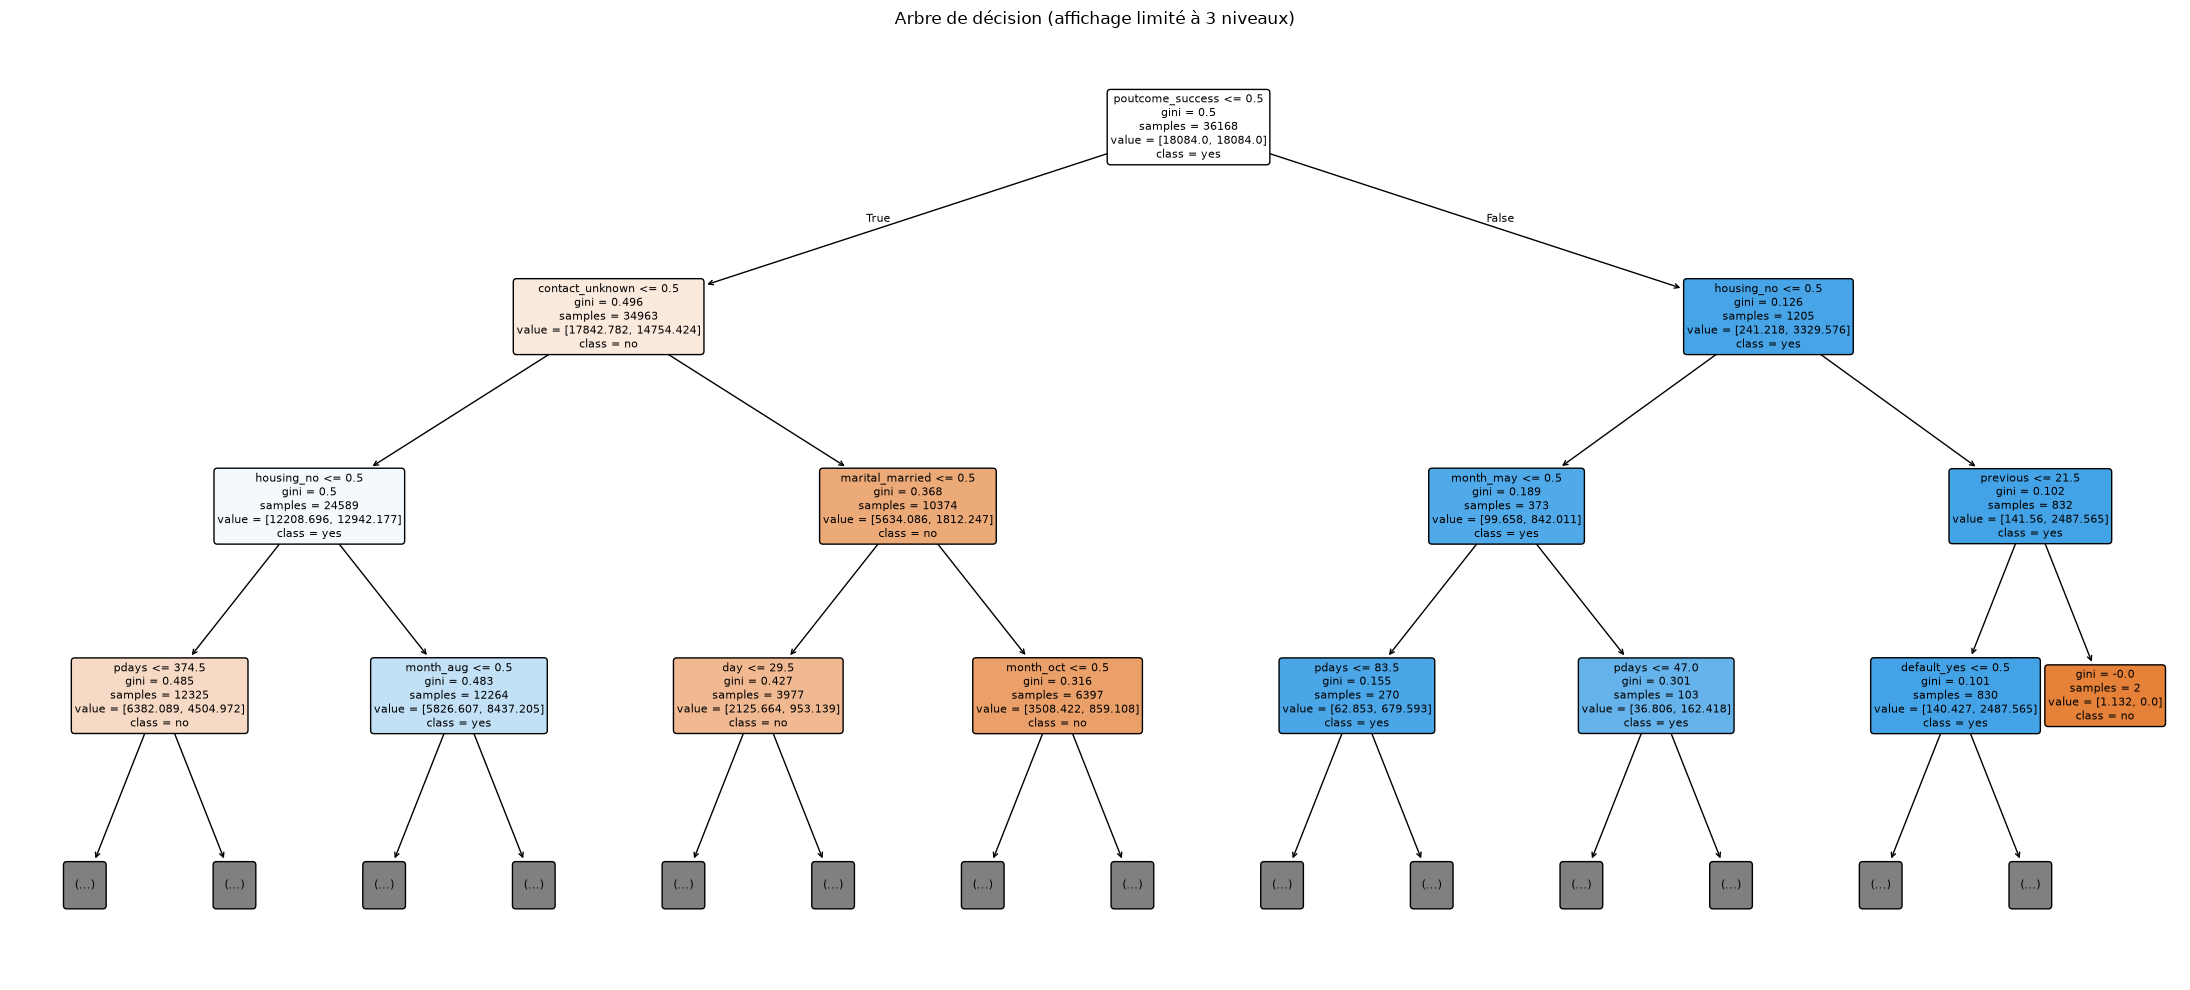

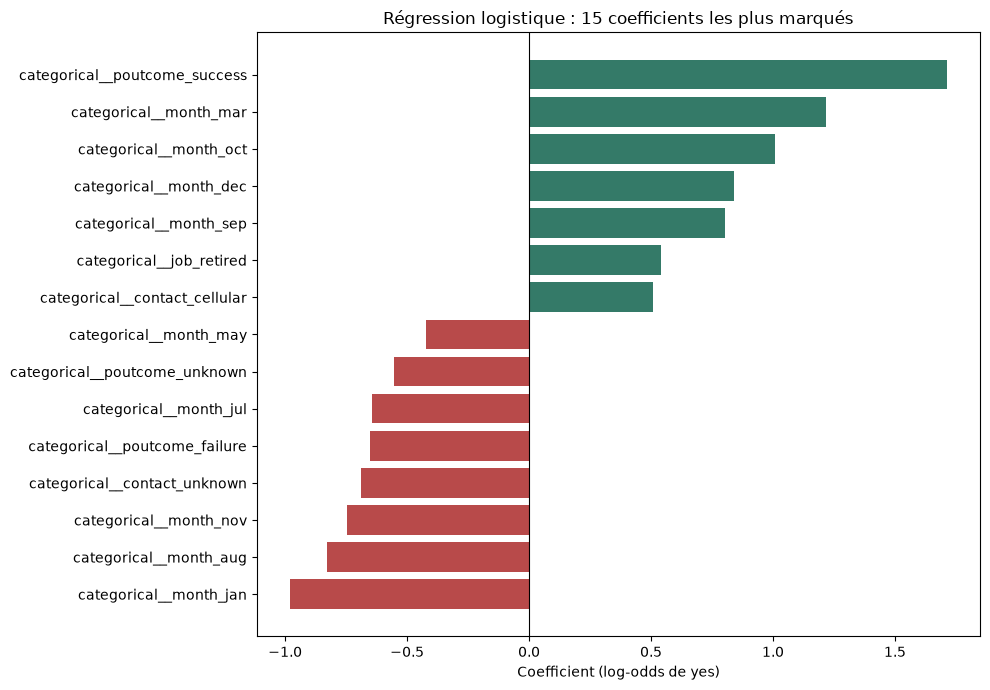

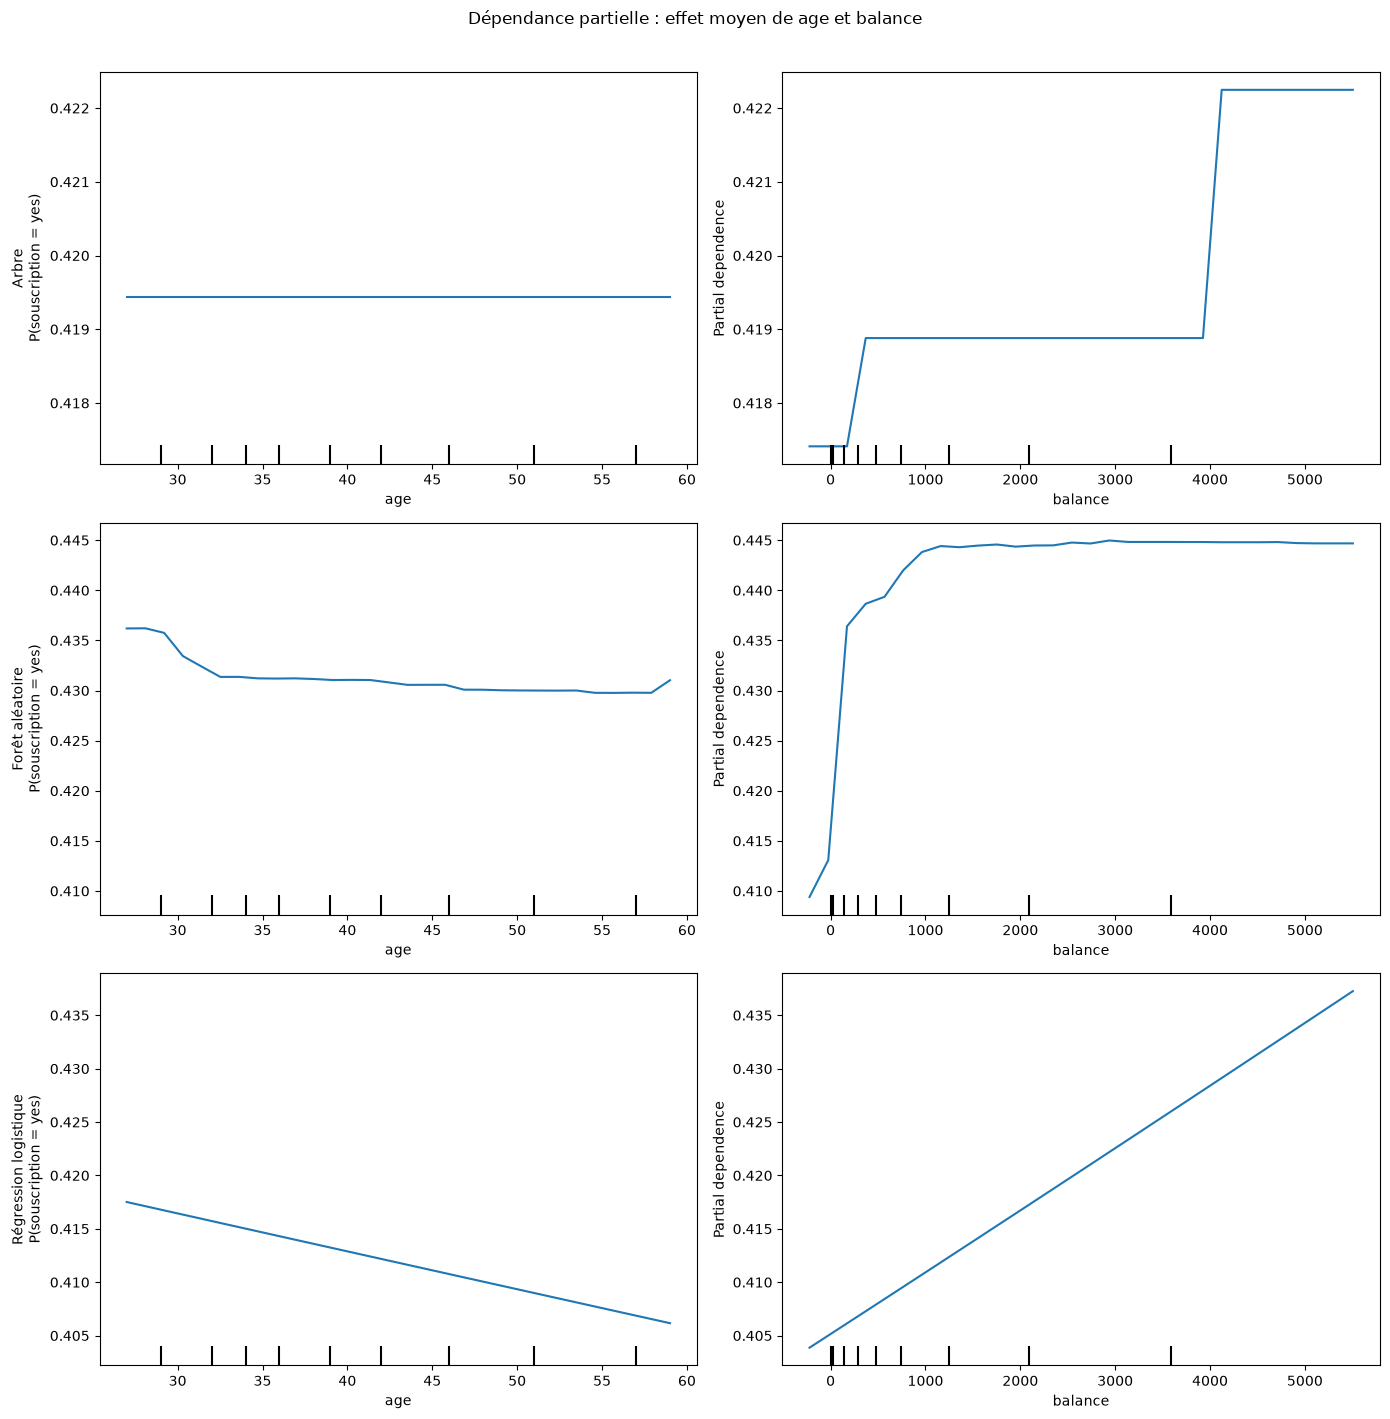

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.inspection import PartialDependenceDisplay
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Pour rendre les seuils de l'arbre lisibles, on ne standardise pas les numériques.
preprocessor_arbre = ColumnTransformer(
    transformers=[
        ("numeric", "passthrough", numeric_features),
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ],
    verbose_feature_names_out=False,
)
arbre_visualisation = Pipeline(
    steps=[
        ("preprocessing", preprocessor_arbre),
        ("classifier", DecisionTreeClassifier(
            max_depth=5, class_weight="balanced", random_state=42
        )),
    ]
)
arbre_visualisation.fit(X_train, y_train)

noms_variables_arbre = arbre_visualisation.named_steps[
    "preprocessing"
].get_feature_names_out()
plt.figure(figsize=(22, 10))
plot_tree(
    arbre_visualisation.named_steps["classifier"],
    feature_names=noms_variables_arbre,
    class_names=[str(classe) for classe in arbre_visualisation.classes_],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8,
)
plt.title("Arbre de décision (affichage limité à 3 niveaux)")
plt.tight_layout()
plt.show()

# Coefficients de la régression logistique associés à la classe yes.
modele_logistique_visualisation = models["Régression logistique"]
modele_logistique_visualisation.fit(X_train, y_train)
classifieur_logistique = modele_logistique_visualisation.named_steps["classifier"]
coefficients = classifieur_logistique.coef_[0].copy()
if classifieur_logistique.classes_[1] != "yes":
    coefficients *= -1
noms_variables_logistique = modele_logistique_visualisation.named_steps[
    "preprocessing"
].get_feature_names_out()
coefficients = pd.Series(coefficients, index=noms_variables_logistique)
coefficients_affiches = coefficients.loc[
    coefficients.abs().nlargest(15).index
].sort_values()

plt.figure(figsize=(10, 7))
couleurs = ["#b84a4a" if valeur < 0 else "#347a68" for valeur in coefficients_affiches]
plt.barh(coefficients_affiches.index, coefficients_affiches.values, color=couleurs)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Coefficient (log-odds de yes)")
plt.title("Régression logistique : 15 coefficients les plus marqués")
plt.tight_layout()
plt.show()

# Les PDP montrent une variation moyenne, pas une explication causale individuelle.
modele_foret_visualisation = models["Forêt aléatoire"]
modele_foret_visualisation.fit(X_train, y_train)
modeles_pdp = {
    "Arbre": arbre_visualisation,
    "Forêt aléatoire": modele_foret_visualisation,
    "Régression logistique": modele_logistique_visualisation,
}
X_pdp = X_train.sample(n=min(1000, len(X_train)), random_state=42).copy()
X_pdp["age"] = X_pdp["age"].astype(float)
X_pdp["balance"] = X_pdp["balance"].astype(float)
fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(14, 14))
for ligne, (nom, estimateur) in enumerate(modeles_pdp.items()):
    PartialDependenceDisplay.from_estimator(
        estimateur,
        X_pdp,
        features=["age", "balance"],
        response_method="predict_proba",
        grid_resolution=30,
        ax=axes[ligne],
    )
    axes[ligne, 0].set_ylabel(f"{nom}\nP(souscription = yes)")

fig.suptitle("Dépendance partielle : effet moyen de age et balance", y=1.01)
plt.tight_layout()
plt.show()

## 11. Évaluer une seule fois sur le test final

Après avoir choisi le modèle à partir des résultats de validation croisée, on l'entraîne sur tout le jeu d'entraînement et on mesure ses performances sur `X_test`. Ce jeu de test n'a pas servi au choix du modèle.

La matrice de confusion montre les types d'erreurs. Le rappel de `yes` mesure la part des souscripteurs détectés ; la précision de `yes` mesure la part des souscriptions parmi les clients signalés. Le meilleur compromis dépend de l'objectif et du coût des appels.

In [8]:
from sklearn.metrics import classification_report, confusion_matrix

# Ajustement final sur toutes les données d'entraînement, puis test une seule fois.
best_model.fit(X_train, y_train)
y_test_pred = best_model.predict(X_test)

print(f"=== ÉVALUATION FINALE : {best_model_name} ===\n")
print(
    classification_report(
        y_test,
        y_test_pred,
        labels=["no", "yes"],
        target_names=["No (pas de souscription)", "Yes (souscription)"],
        zero_division=0,
    )
)

matrice_confusion = pd.DataFrame(
    confusion_matrix(y_test, y_test_pred, labels=["no", "yes"]),
    index=["Réel : no", "Réel : yes"],
    columns=["Prédit : no", "Prédit : yes"],
)
display(matrice_confusion)

=== ÉVALUATION FINALE : Forêt aléatoire ===

                          precision    recall  f1-score   support

No (pas de souscription)       0.94      0.78      0.85      7985
      Yes (souscription)       0.28      0.64      0.39      1058

                accuracy                           0.76      9043
               macro avg       0.61      0.71      0.62      9043
            weighted avg       0.86      0.76      0.80      9043



,Prédit : no,Prédit : yes
Réel : no,6209,1776
Réel : yes,382,676


## Bilan et prochaines étapes

Dans cette expérience, la forêt aléatoire arrive en tête de la comparaison par validation croisée. Sur le test final, elle détecte 676 des 1 058 souscriptions (rappel d'environ 0,64), mais 1 776 clients prédits `yes` n'ont pas souscrit ; la précision est donc d'environ 0,28. Le modèle privilégie ici le repérage des souscripteurs, au prix de nombreux faux positifs.

Ces chiffres dépendent du partage aléatoire, des variables retenues et du seuil de décision par défaut. Ils ne garantissent pas les mêmes performances sur une campagne future. Pour continuer, il faudra choisir le seuil à partir d'une validation indépendante selon le coût d'un appel et celui d'une souscription manquée ; si des dates complètes sont disponibles, tester également une séparation temporelle. Le jeu de test utilisé ici ne doit pas servir à régler ces choix.